In [2]:
import osmnx as ox

import pandas as pd
import geopandas as gpd
import shapely
import pyrosm

pd.set_option("display.max_columns", None)

In [151]:
fp = "chile-latest.osm.pbf"
place_name = "Provincia de Concepción, Chile"

place_string = "_".join(place_name.lower().split(",")[0].split(" "))

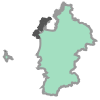

In [157]:
area_gdf = ox.geocode_to_gdf(place_name)
area = area_gdf.geometry.iloc[0]
area

In [156]:
# define the keys you want to query through a <key>: <value> dict

# the <value> for each <key> can be a list (i.e. ["hospital", "pharmacy"])
# also it can be True if you want to download all features with <key>

tags = {
    "amenity": True
    # add other keys like "shop": True if you want
}

In [ ]:
# load the file with all osm data and clip with boundary
osm = pyrosm.OSM(fp, bounding_box=area)

# download the features
pois = osm.get_pois(custom_filter=tags)

pois = pois.to_crs(32718)
pois.geometry = pois.geometry.centroid
pois = pois.to_crs(4326)

pois = pois[~pois["amenity"].isna()]
pois = pois[pois['amenity'] != 'bench']

pois.lon = pois.geometry.x
pois.lat = pois.geometry.y
pois = pois.rename(columns={"lon": "x", "lat": "y"})

pois = pois[["id", "x", "y", "amenity", "geometry"]]

In [148]:
pois.amenity.value_counts().to_dict()

{'parking': 595,
 'school': 585,
 'place_of_worship': 326,
 'restaurant': 310,
 'fast_food': 256,
 'pharmacy': 156,
 'waste_basket': 154,
 'kindergarten': 151,
 'doctors': 102,
 'fuel': 87,
 'community_centre': 83,
 'cafe': 80,
 'bank': 78,
 'clinic': 77,
 'waste_disposal': 76,
 'parking_entrance': 62,
 'toilets': 51,
 'bar': 51,
 'pub': 47,
 'social_facility': 45,
 'courthouse': 44,
 'recycling': 41,
 'fire_station': 40,
 'fountain': 38,
 'taxi': 37,
 'dentist': 36,
 'police': 35,
 'veterinary': 32,
 'bus_station': 31,
 'atm': 30,
 'post_office': 28,
 'university': 27,
 'bicycle_parking': 26,
 'nightclub': 23,
 'college': 18,
 'hospital': 17,
 'theatre': 16,
 'car_rental': 16,
 'car_wash': 15,
 'marketplace': 15,
 'townhall': 14,
 'ice_cream': 14,
 'library': 13,
 'events_venue': 12,
 'parking_space': 9,
 'arts_centre': 9,
 'shelter': 9,
 'bicycle_repair_station': 8,
 'prison': 8,
 'telephone': 6,
 'childcare': 6,
 'cinema': 5,
 'love_hotel': 5,
 'charging_station': 5,
 'social_centre

In [119]:
edges_gdf = gpd.read_file("./network/provincia_de_concepción.gpkg", layer="edges", encoding="latin-1")

In [149]:
pois.amenity.value_counts().to_dict()

{'parking': 595,
 'school': 585,
 'place_of_worship': 326,
 'restaurant': 310,
 'fast_food': 256,
 'pharmacy': 156,
 'waste_basket': 154,
 'kindergarten': 151,
 'doctors': 102,
 'fuel': 87,
 'community_centre': 83,
 'cafe': 80,
 'bank': 78,
 'clinic': 77,
 'waste_disposal': 76,
 'parking_entrance': 62,
 'toilets': 51,
 'bar': 51,
 'pub': 47,
 'social_facility': 45,
 'courthouse': 44,
 'recycling': 41,
 'fire_station': 40,
 'fountain': 38,
 'taxi': 37,
 'dentist': 36,
 'police': 35,
 'veterinary': 32,
 'bus_station': 31,
 'atm': 30,
 'post_office': 28,
 'university': 27,
 'bicycle_parking': 26,
 'nightclub': 23,
 'college': 18,
 'hospital': 17,
 'theatre': 16,
 'car_rental': 16,
 'car_wash': 15,
 'marketplace': 15,
 'townhall': 14,
 'ice_cream': 14,
 'library': 13,
 'events_venue': 12,
 'parking_space': 9,
 'arts_centre': 9,
 'shelter': 9,
 'bicycle_repair_station': 8,
 'prison': 8,
 'telephone': 6,
 'childcare': 6,
 'cinema': 5,
 'love_hotel': 5,
 'charging_station': 5,
 'social_centre

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

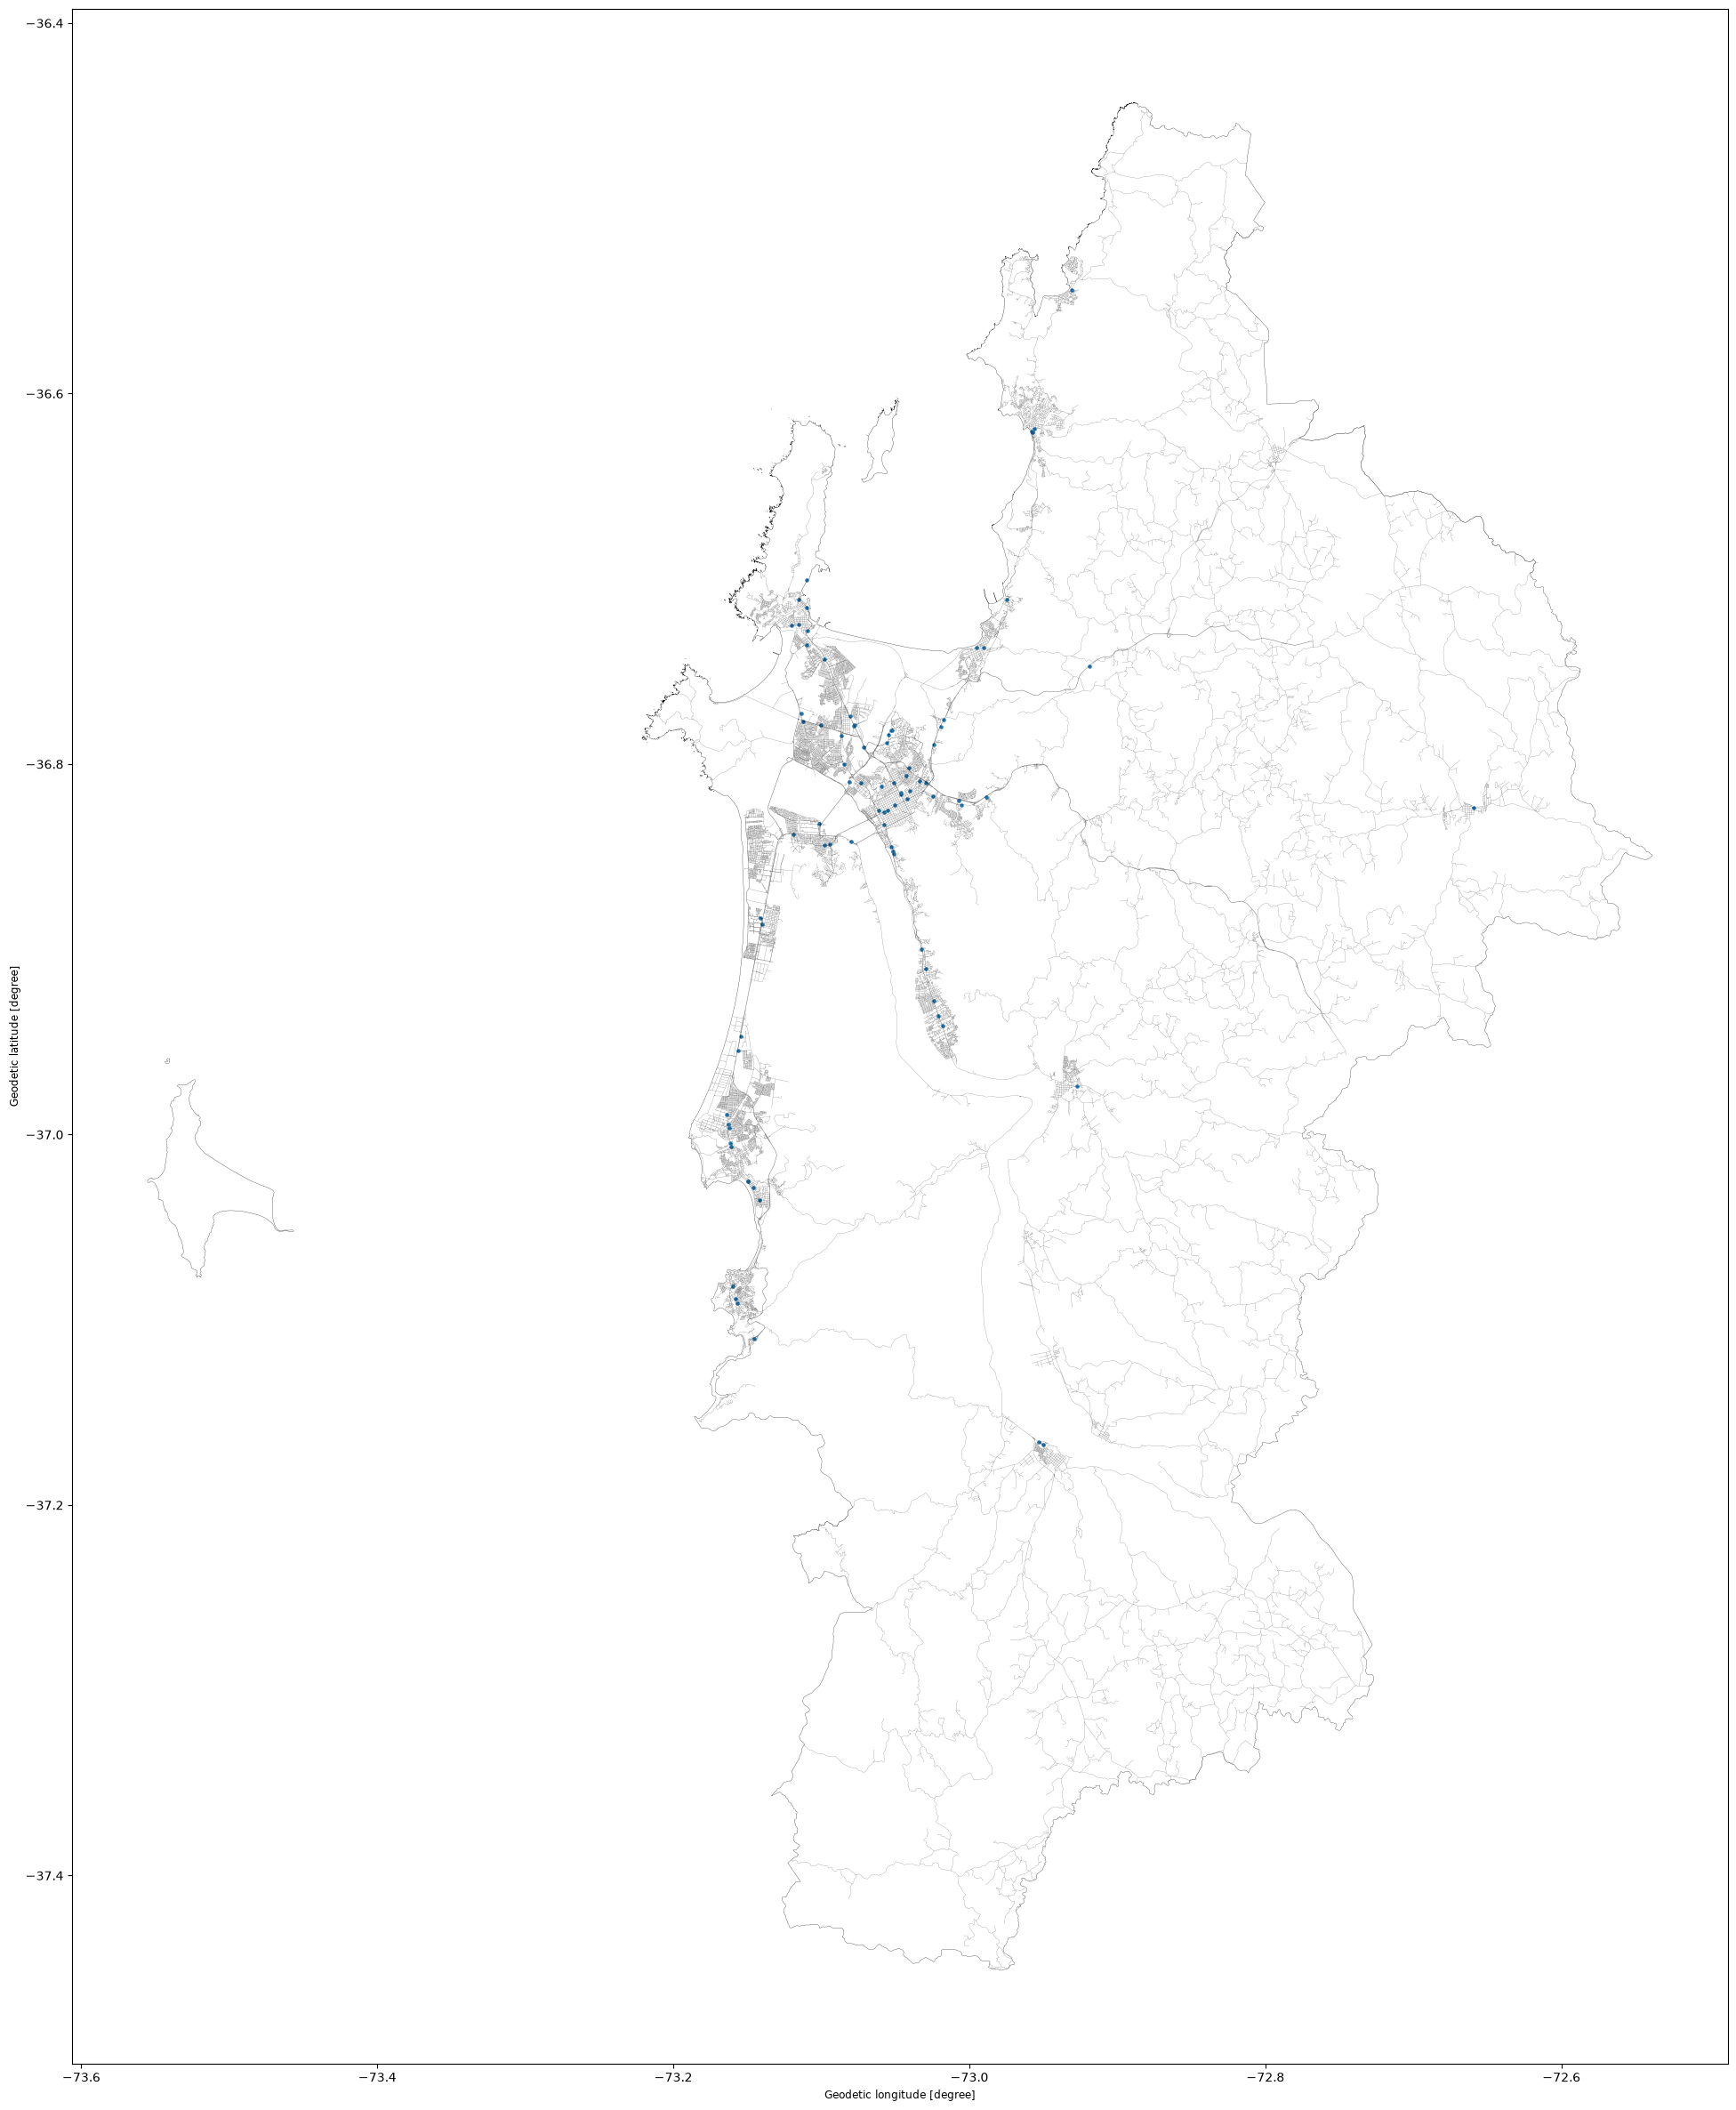

In [140]:
ax = pois[pois.amenity == "fuel"].plot(figsize=(30,30), markersize=5)
edges_gdf.plot(ax=ax, color="black", linewidth=0.1)
area_gdf.plot(ax=ax, color="none", linewidth=0.2)

In [155]:
pois.to_parquet(f"pois/pois_{place_string}.parquet")